# 🤖 Transformer Tutorial — "Attention Is All You Need"

This notebook walks through the key ideas from the original Transformer paper
([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)) step-by-step, with
runnable code and visualizations.

**Roadmap:**
1. **Attention Intuition** — What is attention, at the simplest level?
2. **RNN vs. Transformer** — Why parallelism matters
3. **Decoder Layer** — Self-attention, cross-attention, feed-forward
4. **Feed-Forward Network** — The "expand → activate → compress" pattern
5. **Byte Pair Encoding (BPE)** — How raw text becomes tokens
6. **Embeddings** — From token IDs to dense vectors
7. **Positional Encoding** — Giving the model a sense of order
8. **Full Transformer** — Putting it all together

## 0. Imports

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import MultiheadAttention

print(f"PyTorch {torch.__version__}")

## 1. Attention Intuition

**Core idea:** Given a *query* (what I'm looking for), compute a similarity
score against every *key*, then use those scores to take a weighted sum of
the *values*.

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right) V$$

In the toy example below we skip the learned projections and use raw vectors
so you can see the dot-product → softmax → weighted-sum pipeline directly.

In [4]:

# A sequence of 5 words - encoder input
keys = torch.tensor([
    [1.0, 0.0, 0.0], # Word 0
    [0.5, 0.5, 0.0], # Word 1
    [0.0, 1.0, 0.0], # Word 2 (Target)
    [0.0, 0.5, 0.5], # Word 3
    [0.0, 0.0, 1.0], # Word 4
])

values = keys.clone() # For simplicity, Values = Keys

# Decoder's current state
query = torch.tensor([0.0, 1.0, 0.0]) # the decoder wants something like word 2

# Dot product: we calculate q . K for all 5 words
raw_scores = torch.matmul(keys, query)
print(f"Raw Scores: {raw_scores}")

# Softmax: Convert to probabilities
weights = F.softmax(raw_scores * 5, dim=0) # Multiply by 5 to sharpen the peak
print(f"Attention Weights: {weights}")

# Weighted Sum
context = torch.matmul(weights, values)
print(f"Context Vector: {context}")
# The result will look very similar to Word 20 ([0, 1, 0])

Raw Scores: tensor([0.0000, 0.5000, 1.0000, 0.5000, 0.0000])
Attention Weights: tensor([0.0057, 0.0697, 0.8492, 0.0697, 0.0057])
Context Vector: tensor([0.0406, 0.9189, 0.0406])


## 2. RNN vs. Transformer — Sequential vs. Parallel

**RNN:** Processes words one at a time. Each step depends on the previous hidden
state, so it **cannot** be parallelized. Information about early words must
survive through a bottleneck hidden state.

**Transformer:** Processes all words **simultaneously** via matrix
multiplication. Every word can directly attend to every other word — no
bottleneck.

| | RNN | Transformer |
|---|---|---|
| Processing | Sequential (step-by-step) | Parallel (all at once) |
| Long-range dependencies | Difficult (vanishing gradients) | Easy (direct attention) |
| Training speed | Slow | Fast (GPU-friendly) |

Below we simulate both side-by-side.

In [10]:
# ----------------------------------
# Python Simulation of the RNN Loop
# ----------------------------------
import numpy as np

# A sequence of 5 words
words = ["The", "cat", "sat", "on", "mat"]
d_model = 4 # Dimension of the vector representation

# Random input embeddings (X)
X = np.random.randn(len(words), d_model)

# RNN Weights
W_h = np.random.randn(d_model, d_model) # Hidden-to-Hidden
W_x = np.random.randn(d_model, d_model) # Input-to-Hidden

# Initial hidden state (memory)
h_t = np.zeros(d_model)

print("--- RNN Sequential Processing ---")
rnn_outputs = []
for i, word in enumerate(words):
    # 1. Update state based on previous state (h_t) and current input (X[i])
    input_part = np.dot(X[i], W_x)
    hidden_part = np.dot(h_t, W_h)

    # 2. Apply activation (tanh)
    h_t = np.tanh(input_part + hidden_part)
    rnn_outputs.append(h_t)

    print(f"Step {i+1}: Processed '{word}'. Hidden state is {h_t}. Updated hidden state.")

rnn_outputs = np.array(rnn_outputs)


--- RNN Sequential Processing ---
Step 1: Processed 'The'. Hidden state is [-0.81159085 -0.37732438  0.8533347  -0.67932143]. Updated hidden state.
Step 2: Processed 'cat'. Hidden state is [-0.99990712  0.96317842 -0.19378582  0.90896195]. Updated hidden state.
Step 3: Processed 'sat'. Hidden state is [ 0.82950317 -0.26893159  0.97003716  0.34956348]. Updated hidden state.
Step 4: Processed 'on'. Hidden state is [-0.09047316  0.42357517 -0.9471669   0.44081187]. Updated hidden state.
Step 5: Processed 'mat'. Hidden state is [ 0.9953754  -0.18800982  0.38626605  0.42784323]. Updated hidden state.


In [ ]:
# ----------------------------------
# Transformer Parallel Processing
# ----------------------------------

# Transformer Weights (learned projection matrices)
W_Q = np.random.randn(d_model, d_model)  # Query projection
W_K = np.random.randn(d_model, d_model)  # Key projection
W_V = np.random.randn(d_model, d_model)  # Value projection

# Project entire sequence into Q, K, V simultaneously
# X shape: [5, 4] @ W shape: [4, 4] -> [5, 4]
Q = np.dot(X, W_Q)  # What am I looking for?
K = np.dot(X, W_K)  # What do I contain?
V = np.dot(X, W_V)  # What do I return if matched?

# Compute alignment scores in ONE massive multiplication
# scores shape: [5, 5] — every word's similarity to every other word
scores = np.dot(Q, K.T) / np.sqrt(d_model)

# Apply Softmax to get probabilities (rows sum to 1)
def softmax(x):
    e_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return e_x / np.sum(e_x, axis=-1, keepdims=True)

attention_weights = softmax(scores)

# Compute Output (Weighted Sum of Values)
output = np.dot(attention_weights, V)

print("Computed Attention for ALL words simultaneously!")
print(f"Q shape: {Q.shape}, K shape: {K.shape}, V shape: {V.shape}")
print(f"Attention Weights shape: {attention_weights.shape}")
print(f"Output shape: {output.shape}")

Compute Attention for ALL words simultaneously
Attention Weights Matrix Shape: (5, 5)


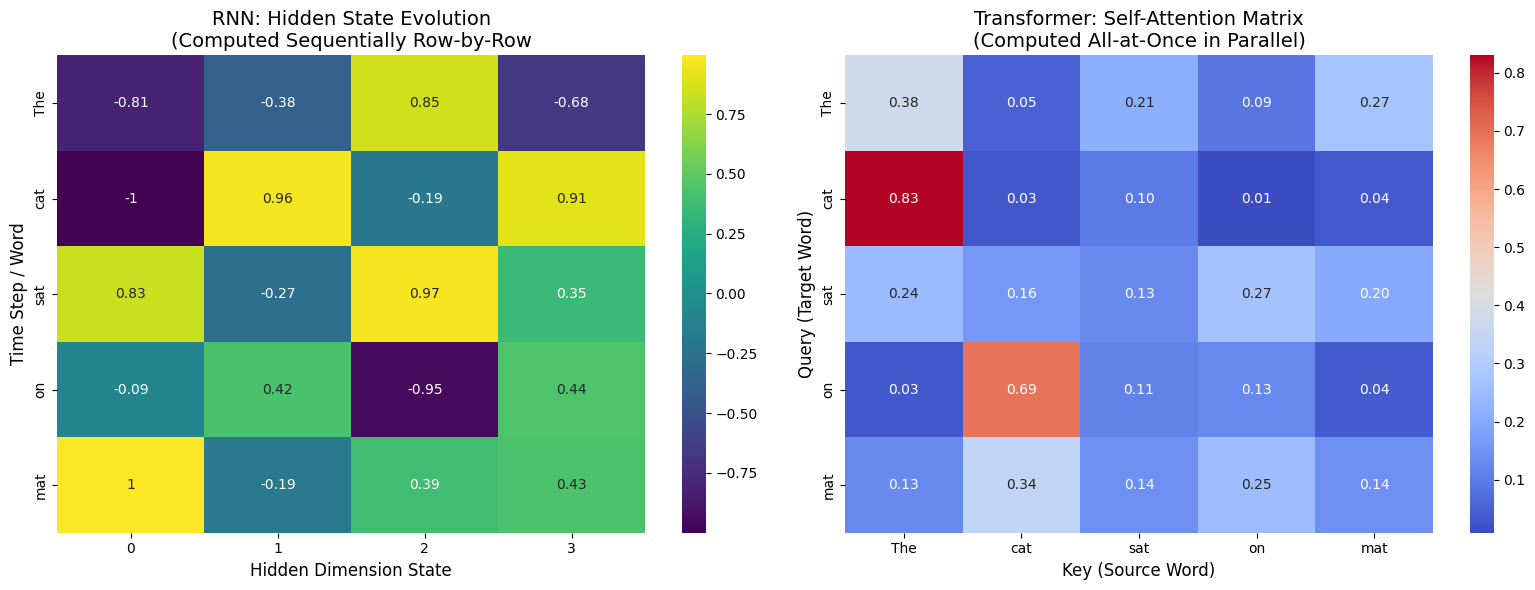

In [ ]:
# Plotting the comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: RNN Hidden States
sns.heatmap(rnn_outputs, ax=axes[0], cmap="viridis", annot=True, cbar=True,
            yticklabels=words)
axes[0].set_title("RNN: Hidden State Evolution\n(Computed Sequentially Row-by-Row", fontsize=14)
axes[0].set_ylabel("Time Step / Word", fontsize=12)
axes[0].set_xlabel("Hidden Dimension State", fontsize=12)

# Plot 2: Transformer Attention Weights
sns.heatmap(attention_weights, ax=axes[1], cmap="coolwarm", annot=True, fmt=".2f", cbar=True,
            xticklabels=words, yticklabels=words)
axes[1].set_title("Transformer: Self-Attention Matrix\n(Computed All-at-Once in Parallel)", fontsize=14)
axes[1].set_xlabel("Key (Source Word)", fontsize=12)
axes[1].set_ylabel("Query (Target Word)", fontsize=12)

plt.tight_layout()
plt.show()


## 3. Decoder Layer — The Three Sub-Blocks

Each decoder layer has **three** sub-blocks, each followed by a residual
connection and layer normalization:

```
┌─────────────────────────────────────┐
│  A. Masked Self-Attention           │  ← decoder attends to itself
│     + Residual & LayerNorm          │    (Q=K=V=tgt, with causal mask)
├─────────────────────────────────────┤
│  B. Encoder-Decoder (Cross) Attn    │  ← decoder queries the encoder
│     + Residual & LayerNorm          │    (Q=tgt, K=V=memory)
├─────────────────────────────────────┤
│  C. Position-wise Feed-Forward      │  ← independent per-position MLP
│     + Residual & LayerNorm          │
└─────────────────────────────────────┘
```

**Why a mask in (A)?** During training the decoder sees the full target sentence, but
at inference it generates one token at a time. The causal mask prevents position *i*
from attending to future positions *i+1, i+2, …* — preserving the autoregressive property.

In [ ]:
class DecoderLayer(nn.Module):

    def __init__(self, d_model, nhead, dim_feedforward=2048, dropout=0.1):
        super().__init__()

        # Self-Attention (Decoder looks at itself)
        self.self_attn = MultiheadAttention(d_model, nhead, dropout=dropout)

        # Encoder-Decoder Attention (The Bridge)
        self.multihead_attn = MultiheadAttention(d_model, nhead, dropout=dropout)

        # Feed Forward
        self.linear1 = nn.Linear(d_model, dim_feedforward)
        self.dropout = nn.Dropout(dropout)
        self.linear2 = nn.Linear(dim_feedforward, d_model)

        # Norms
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)

    def forward(self, tgt, memory, tgt_mask=None, memory_mask=None):
        """
        tgt: The decoder input (target sequence so far) -> Serves as Query
        memory: The encoder output (full source sequence) -> Serves as Key and Value
        """

        # A. Self-Attention Block (Decoder attending to itself)
        tgt2, _ = self.self_attn(tgt, tgt, tgt, attn_mask=tgt_mask)
        tgt = tgt + self.dropout1(tgt2)
        tgt = self.norm1(tgt)

        # B. Encoder-Decoder Attention Block (The Bridge)
        # query = tgt (from decoder)
        # key   = memory (from encoder)
        # value = memory (from encoder)
        tgt2, _ = self.multihead_attn(query=tgt, key=memory, value=memory,
                                      key_padding_mask=memory_mask)

        # Residual Connection & Norm
        tgt = tgt + self.dropout2(tgt2)
        tgt = self.norm2(tgt)

        # C. Feed-Forward Block
        tgt2 = self.linear2(self.dropout(torch.relu(self.linear1(tgt))))
        tgt = tgt + self.dropout3(tgt2)
        return self.norm3(tgt)


## 4. Position-wise Feed-Forward Network

Each position passes through the same two-layer MLP independently:

$$\text{FFN}(x) = W_2 \cdot \text{ReLU}(W_1 x + b_1) + b_2$$

- $W_1$: **expands** from `d_model` → `d_ff` (paper: 512 → 2048, a 4× expansion)
- ReLU: introduces non-linearity and sparsity
- $W_2$: **compresses** back from `d_ff` → `d_model`

Think of it as "unzipping" the representation into a larger workspace where the
model can do complex feature mixing, then "re-zipping" it back down.

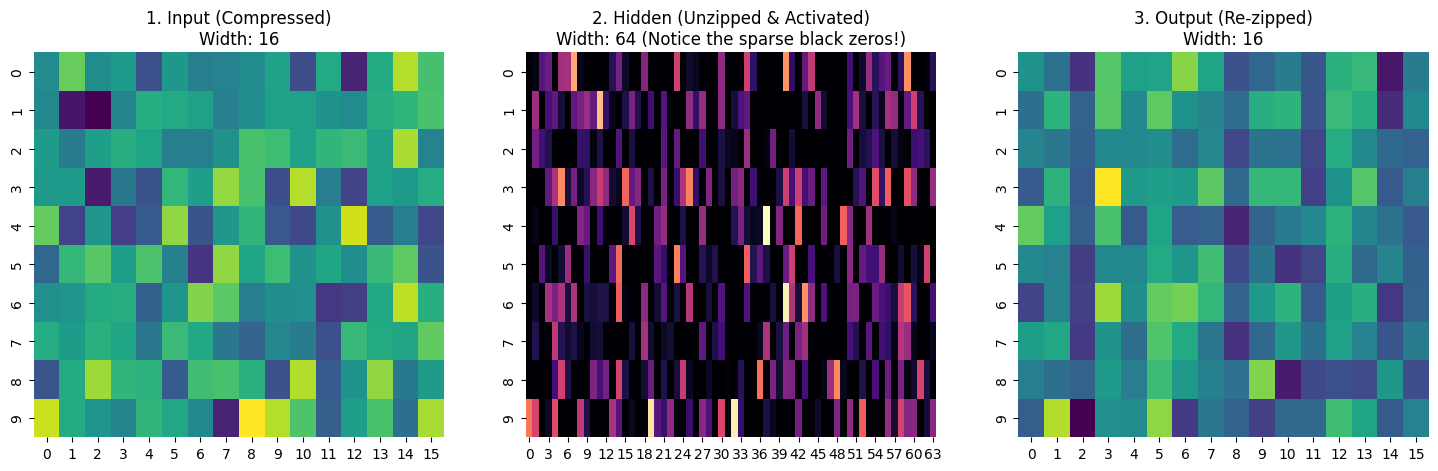

In [20]:
# Visual Proof: The "Unzipping" Visualization

# Defining the Position-wise Feed-forward Network
class PositionwiseFeedForward(nn.Module):

    def __init__(self, d_model, d_ff):
        super().__init__()
        # W1: Expansion (e.g., 16 -> 64)
        self.w_1 = nn.Linear(d_model, d_ff)
        # W2: Compression (e.g., 64 -> 16)
        self.w_2 = nn.Linear(d_ff, d_model)
        # Activation
        self.relu = nn.ReLU()

    def forward(self, x):
        # Apply expansion, activation, then compression
        return self.w_2(self.relu(self.w_1(x)))
    
# Setup parameters for visualization
d_model = 16
d_ff = 64
seq_len = 10

# Initialize and run
model = PositionwiseFeedForward(d_model, d_ff)
input_data = torch.randn(1, seq_len, d_model)

# Extract the expanded state to visualize it
with torch.no_grad():
    expanded_state = model.relu(model.w_1(input_data))
    output_data = model(input_data)

# --- Plotting ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Input (Compressed)
sns.heatmap(input_data.squeeze().numpy(), ax=axes[0], cmap='viridis', cbar=False)
axes[0].set_title(f"1. Input (Compressed)\nWidth: {d_model}")

# Plot 2: Hidden (Expanded workspace)
sns.heatmap(expanded_state.squeeze().numpy(), ax=axes[1], cmap="magma", cbar=False)
axes[1].set_title(f"2. Hidden (Unzipped & Activated)\nWidth: {d_ff} (Notice the sparse black zeros!)")

# Plot 3: Output (Re-compressed)
sns.heatmap(output_data.squeeze().numpy(), ax=axes[2], cmap="viridis", cbar=False)
axes[2].set_title(f"3. Output (Re-zipped)\nWidth: {d_model}")

plt.show()

## 5. Byte Pair Encoding (BPE) — From Text to Tokens

Before anything enters the Transformer, raw text must be **tokenized**.
BPE works by iteratively merging the most frequent pair of adjacent symbols:

1. Start with individual characters + end-of-word marker `</w>`
2. Count all adjacent pairs (weighted by word frequency)
3. Merge the most frequent pair → add new token to vocabulary
4. Repeat until vocabulary reaches target size

This lets the model handle **any** word — common words become single tokens,
rare words get broken into known subwords.

In [ ]:
# Byte Pair Encoding (BPE) — Full Iterative Demo
import re, collections

def get_stats(vocab):
    """Count frequency of all adjacent symbol pairs, weighted by word frequency."""
    pairs = collections.defaultdict(int)
    for word, freq in vocab.items():
        symbols = word.split()
        for i in range(len(symbols) - 1):
            pairs[symbols[i], symbols[i + 1]] += freq
    return pairs

def merge_vocab(pair, v_in):
    """Merge every occurrence of a symbol pair in the vocabulary."""
    v_out = {}
    bigram = re.escape(' '.join(pair))
    p = re.compile(r'(?<!\S)' + bigram + r'(?!\S)')
    for word in v_in:
        w_out = p.sub(''.join(pair), word)
        v_out[w_out] = v_in[word]
    return v_out

# Initial vocabulary: each word split into characters, with word frequencies
vocab = {
    'l o w </w>': 5,        # "low" appears 5 times in corpus
    'l o w e r </w>': 2,    # "lower" appears 2 times
    'n e w e s t </w>': 6,  # "newest" appears 6 times
    'w i d e s t </w>': 3,  # "widest" appears 3 times
}

num_merges = 8  # Number of BPE merge operations to perform

print("=== BPE Merge Steps ===\n")
print(f"Initial vocab: {vocab}\n")

for i in range(num_merges):
    pairs = get_stats(vocab)
    if not pairs:
        print("No more pairs to merge!")
        break
    best = max(pairs, key=pairs.get)
    print(f"Step {i+1}: Merge '{best[0]}' + '{best[1]}' → '{best[0]}{best[1]}'  "
          f"(frequency: {pairs[best]})")
    vocab = merge_vocab(best, vocab)
    print(f"  Vocab: {vocab}\n")

Most frequent pair: ('e', 's')
New Vocab: {'l o w </w>': 5, 'l o w e r </w>': 2, 'n e w es t </w>': 6, 'w i d es t </w>': 3}


## 6. Embeddings — From Token IDs to Vectors

After BPE gives us integer token IDs, we need to convert them into dense vectors
the model can work with. This is done with a learned **embedding table** of shape
`(vocab_size, d_model)`.

The paper also **scales** the embeddings by $\sqrt{d_{model}}$ to keep their
magnitude balanced with the positional encodings that get added next.

In [ ]:
class Embeddings(nn.Module):
    def __init__(self, d_model, vocab):
        super().__init__()
        # The embedding lookup table (The shared weight matrix)
        self.lut = nn.Embedding(vocab, d_model)
        self.d_model = d_model
    
    def forward(self, x):
        # 1. Look up the vector
        # 2. Scale by sqrt(d_model) as per the paper
        return self.lut(x) * math.sqrt(self.d_model)
    
# Simulation
d_model = 512
vocab_size = 10_000
emb_layer = Embeddings(d_model, vocab_size)

# Input: Batch of 1 sentence, 3 tokens [Index 4, Index 20, Index 99]
input_tokens = torch.tensor([[4, 20, 99]])
vector_output = emb_layer(input_tokens)

print(f"Input shape: {input_tokens.shape}") # [1, 3]
print(f"Output shape: {vector_output.shape}") # [1, 3, 512]


Input shape: torch.Size([1, 3])
Output shape: torch.Size([1, 3, 512])


## 7. Positional Encoding — Giving the Model a Sense of Order

Attention is **permutation-invariant** — "cat sat on mat" and "mat on sat cat"
would produce identical attention scores! We fix this by adding a **positional
encoding** to each embedding.

The paper uses fixed sinusoidal functions (no learned parameters):

$$PE_{(pos, 2i)}   = \sin\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$
$$PE_{(pos, 2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

Each dimension oscillates at a different frequency, creating a unique "fingerprint"
for every position. This also lets the model generalize to sequence lengths
longer than those seen during training.

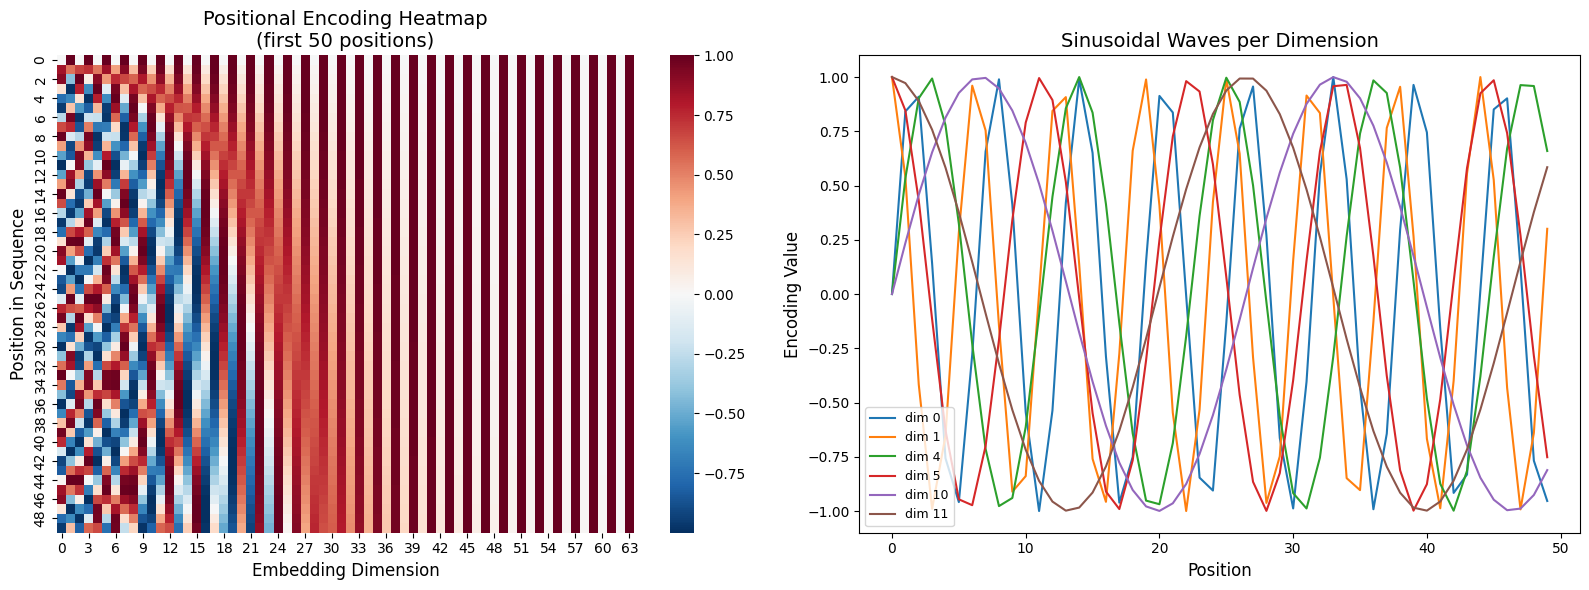

PE shape: torch.Size([1, 100, 64])
Each position gets a unique 'fingerprint' that the model can use to know word order.


In [25]:
import torch
import torch.nn as nn
import math
import matplotlib.pyplot as plt
import seaborn as sns

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * -(math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)  # Even dimensions
        pe[:, 1::2] = torch.cos(position * div_term)  # Odd dimensions
        pe = pe.unsqueeze(0)  # [1, max_len, d_model]
        self.register_buffer('pe', pe)

    def forward(self, x):
        # Add positional encoding to embeddings
        return x + self.pe[:, :x.size(1)]

# Visualize the positional encoding pattern
d_model = 64
max_len = 100
pe_layer = PositionalEncoding(d_model, max_len)

# Extract the raw positional encoding values
pe_values = pe_layer.pe.squeeze().numpy()  # [max_len, d_model]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap: each row is a position, each column is a dimension
sns.heatmap(pe_values[:50, :], ax=axes[0], cmap="RdBu_r", cbar=True)
axes[0].set_title("Positional Encoding Heatmap\n(first 50 positions)", fontsize=14)
axes[0].set_xlabel("Embedding Dimension", fontsize=12)
axes[0].set_ylabel("Position in Sequence", fontsize=12)

# Line plot: show a few dimensions over positions
for dim in [0, 1, 4, 5, 10, 11]:
    axes[1].plot(pe_values[:50, dim], label=f"dim {dim}")
axes[1].set_title("Sinusoidal Waves per Dimension", fontsize=14)
axes[1].set_xlabel("Position", fontsize=12)
axes[1].set_ylabel("Encoding Value", fontsize=12)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print(f"PE shape: {pe_layer.pe.shape}")
print("Each position gets a unique 'fingerprint' that the model can use to know word order.")

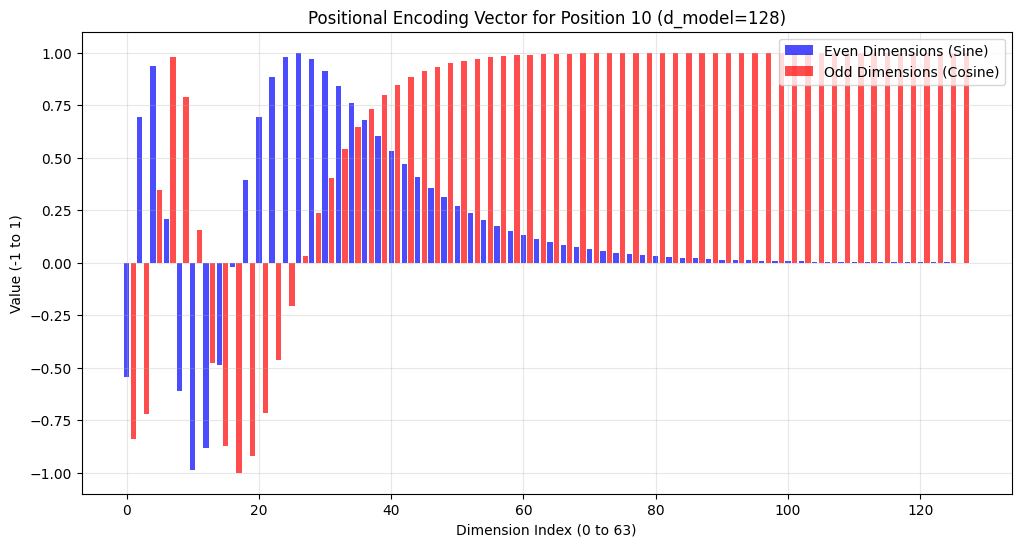

In [44]:
import numpy as np
import matplotlib.pyplot as plt

def get_positional_encoding_vector(pos, d_model):
    """Calculate the PE vector for a single position."""
    pe_vector = np.zeros(d_model)
    
    # Loop through each dimension (0 to d_model-1)
    for k in range(d_model):
        i = k // 2  # The 'i' term (grouping 0,1 then 2,3 etc)
        div_term = 10000 ** (2 * i / d_model)
        
        if k % 2 == 0:
            # Even index: Sine
            pe_vector[k] = np.sin(pos / div_term)
        else:
            # Odd index: Cosine
            pe_vector[k] = np.cos(pos / div_term)
            
    return pe_vector

# --- CONFIGURATION ---
d_model = 128        # Size of the vector
position_to_plot = 10  # We look at the vector for the 10th word

# Generate the vector
vector = get_positional_encoding_vector(position_to_plot, d_model)

# --- PLOTTING ---
plt.figure(figsize=(12, 6))

# We separate even and odd indices for visualization
indices = np.arange(d_model)
even_indices = indices[::2]
odd_indices = indices[1::2]

plt.bar(even_indices, vector[::2], color='blue', label='Even Dimensions (Sine)', alpha=0.7)
plt.bar(odd_indices, vector[1::2], color='red', label='Odd Dimensions (Cosine)', alpha=0.7)

plt.title(f"Positional Encoding Vector for Position {position_to_plot} (d_model={d_model})")
plt.xlabel("Dimension Index (0 to 63)")
plt.ylabel("Value (-1 to 1)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

plt.show()

In [37]:
indices, even_indices, odd_indices

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
        34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
        51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]),
 array([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32,
        34, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 58, 60, 62]),
 array([ 2,  5,  8, 11, 14, 17, 20, 23, 26, 29, 32, 35, 38, 41, 44, 47, 50,
        53, 56, 59, 62]))

## 8. Full Transformer — Putting It All Together

Now we assemble all the pieces into a complete Transformer:

```
Input text
  → BPE tokenization → token IDs
  → Embedding lookup (× √d_model)
  → + Positional Encoding
  → N × Encoder layers  (self-attn → FFN)
  → N × Decoder layers  (masked self-attn → cross-attn → FFN)
  → Linear projection → Softmax → output probabilities
```

Below is a minimal but complete implementation using PyTorch.

In [ ]:
# --- Reusable building blocks ---

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * -(math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])


class Transformer(nn.Module):
    """
    A minimal encoder-decoder Transformer (paper: Section 3).
    """
    def __init__(self, src_vocab, tgt_vocab, d_model=512, nhead=8,
                 num_encoder_layers=6, num_decoder_layers=6,
                 dim_feedforward=2048, dropout=0.1):
        super().__init__()
        self.d_model = d_model

        # --- Embedding + Positional Encoding ---
        self.src_embed = nn.Embedding(src_vocab, d_model)
        self.tgt_embed = nn.Embedding(tgt_vocab, d_model)
        self.pos_enc = PositionalEncoding(d_model, dropout=dropout)

        # --- Encoder & Decoder stacks (PyTorch built-in) ---
        encoder_layer = nn.TransformerEncoderLayer(
            d_model, nhead, dim_feedforward, dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_encoder_layers)

        decoder_layer = nn.TransformerDecoderLayer(
            d_model, nhead, dim_feedforward, dropout, batch_first=True
        )
        self.decoder = nn.TransformerDecoder(decoder_layer, num_decoder_layers)

        # --- Final linear + softmax ---
        self.output_proj = nn.Linear(d_model, tgt_vocab)

    def _generate_causal_mask(self, sz):
        """Upper-triangular mask so position i can only attend to ≤ i."""
        return torch.triu(torch.ones(sz, sz), diagonal=1).bool()

    def forward(self, src, tgt):
        # 1. Embed & scale
        src_emb = self.pos_enc(self.src_embed(src) * math.sqrt(self.d_model))
        tgt_emb = self.pos_enc(self.tgt_embed(tgt) * math.sqrt(self.d_model))

        # 2. Causal mask for decoder self-attention
        tgt_mask = self._generate_causal_mask(tgt.size(1)).to(tgt.device)

        # 3. Encode
        memory = self.encoder(src_emb)

        # 4. Decode
        output = self.decoder(tgt_emb, memory, tgt_mask=tgt_mask)

        # 5. Project to vocabulary
        return self.output_proj(output)


# --- Quick smoke test ---
SRC_VOCAB = 1000
TGT_VOCAB = 1000
D_MODEL = 64       # Small for demo
NHEAD = 4
N_LAYERS = 2

model = Transformer(
    SRC_VOCAB, TGT_VOCAB,
    d_model=D_MODEL, nhead=NHEAD,
    num_encoder_layers=N_LAYERS, num_decoder_layers=N_LAYERS,
    dim_feedforward=128
)

# Fake batch: 2 sentences, source length 10, target length 8
src = torch.randint(0, SRC_VOCAB, (2, 10))
tgt = torch.randint(0, TGT_VOCAB, (2, 8))

logits = model(src, tgt)

print(f"Source shape:  {src.shape}")        # [2, 10]
print(f"Target shape:  {tgt.shape}")        # [2, 8]
print(f"Output logits: {logits.shape}")     # [2, 8, 1000]
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")
